# Relación entre antigüedad vehicular y denuncias de robo o hurto: un análisis por mínimos cuadrados

**Informe técnico de investigación aplicada** · 21 de noviembre de 2026  
**Fuente primaria:** Dirección Nacional de los Registros Nacionales de la Propiedad del Automotor y Créditos Prendarios (DNRPA), República Argentina.  
**Corpus analizado:** 105 archivos mensuales, enero de 2018 a septiembre de 2026.

## Resumen

Se investiga la relación empírica entre la antigüedad de un automotor al momento de la denuncia y la frecuencia de trámites de robo o hurto registrados por la DNRPA. A partir de 328.903 registros individuales se construye un conjunto de 40 pares observacionales $(x_i,y_i)$, donde $x_i$ es la antigüedad calendario en años y $y_i$ es el número de denuncias correspondiente. Se ajustan tres modelos por mínimos cuadrados (lineal, potencial y polinómico cúbico) empleando factorizaciones QR/SVD en lugar de la inversión explícita de la matriz de Gram. La evaluación conjunta emplea SSE, SST, $R^2$, $R^2_{\mathrm{aj}}$, MSE, RMSE, MAE, AIC y BIC sobre una única escala respuesta, complementada con validación cruzada de cinco pliegues y diagnóstico de residuos. El modelo cúbico presenta el menor error fuera de muestra (RMSE ≈ 1,4×10³ denuncias) y captura la estructura no monótona de los datos; la ley potencial, estimada por linealización logarítmica, resulta incompatible con dicha estructura y su error supera ampliamente al de un modelo de media constante. Se documentan las implicancias estadísticas de la linealización, la sensibilidad a la escala y los límites de extrapolación.

**Palabras clave:** mínimos cuadrados ordinarios, regresión polinómica, linealización logarítmica, diagnóstico de residuos, validación cruzada, datos administrativos vehiculares.

---

## 1. Objetivo, alcance y estructura del estudio

El objetivo es cuantificar y comparar modelos de regresión alternativos para describir la frecuencia de denuncias de robo o hurto en función de la antigüedad del vehículo, empleando el criterio de mínimos cuadrados y estableciendo conclusiones sustentadas en evidencia numérica y diagnóstica.

La investigación se organiza en ocho bloques: (i) trazabilidad de la fuente y revisión de la documentación técnica disponible; (ii) caracterización y control de calidad del corpus; (iii) construcción documentada del par observacional; (iv) fundamentación matemática del método; (v) estimación de los tres modelos; (vi) evaluación y validación fuera de muestra; (vii) visualización científica; y (viii) discusión y conclusiones.

Toda afirmación numérica de este documento se genera mediante celdas ejecutables. Los datos crudos se leen sin modificaciones y no se sobrescriben.

## 2. Procedencia, trazabilidad y marco documental

### 2.1 Fuente primaria

Los archivos provienen del conjunto de datos público **«Robos y recuperos de autos»**, publicado por el *Ministerio de Justicia, Subsecretaría de Asuntos Registrales y Dirección Nacional de los Registros Nacionales de la Propiedad del Automotor y Créditos Prendarios*:

- Catálogo oficial: https://datos.gob.ar/dataset/robos-y-recuperos-de-autos
- Página de referencia del organismo: https://www.dnrpa.gov.ar
- Fecha de publicación declarada: 14 de junio de 2018.
- Última actualización del catálogo consultada: 19 de octubre de 2026.
- Contacto institucional declarado: accesobd@dnrpa.gov.ar.

La verificación se realizó el 21 de noviembre de 2026 sobre el catálogo oficial. El repositorio local **no contiene documentación de procedencia**: ni `README.md`, ni `docs/`, ni los propios archivos CSV incorporan metadatos de organismo, URL, licencia o fecha de adquisición. Por consiguiente, la trazabilidad se restablece exclusivamente mediante la consulta externa citada. El catálogo declara «No se ha proporcionado una licencia» y frecuencia de actualización «Sin especificar»; esta información se registra sin inferir derechos de uso adicionales a los declarados por el portal.


In [1]:
from pathlib import Path
from hashlib import sha256
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import KFold
import sklearn, statsmodels, matplotlib, nbformat

SEED = 2026
np.random.seed(SEED)
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
assert RAW.is_dir(), f"No se encuentra el directorio de datos: {RAW}"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 180, "font.size": 10.5,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "legend.fontsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
})
PALETTE = ["#2F5D8C", "#D07A2C", "#3C8D6F", "#8B5B9E"]
DATA_COLOR, FIT_COLORS = PALETTE[0], PALETTE[1:]

print("Entorno de ejecución")
print("  Python:", platform.python_version())
print("  NumPy:", np.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("  SciPy:", stats.__name__, "| scikit-learn:", sklearn.__version__, "| statsmodels:", statsmodels.__version__)
print("  Semilla fija:", SEED)

Entorno de ejecución
  Python: 3.13.17
  NumPy: 2.5.5 | pandas: 3.1.1 | matplotlib: 3.11.2
  SciPy: scipy.stats | scikit-learn: 1.9.1 | statsmodels: 0.15.0
  Semilla fija: 2026


### 2.2 Inventario y huella criptográfica de los archivos originales

Se registra el número de registros y una huella SHA-256 abreviada de cada archivo para preservar la trazabilidad del corpus hasta el nivel de byte. Este inventario permite detectar modificaciones posteriores de la fuente sin alterar los originales.

In [2]:
files = sorted(RAW.glob("dnrpa-robos-recuperos-autos-*.csv"))
inventario = []
for p in files:
    with p.open("rb") as fh:
        digest = sha256(fh.read()).hexdigest()[:16]
    n_lineas = sum(1 for _ in p.open("r", encoding="utf-8-sig", errors="replace")) - 1
    inventario.append({"archivo": p.name, "registros": n_lineas, "sha256_16": digest})
inv = pd.DataFrame(inventario)
print(f"Archivos: {len(inv)} | Registros totales: {inv['registros'].sum():,}")
print(f"Período: {files[0].stem[-6:]} a {files[-1].stem[-6:]}")
display(inv.head(8))
print("... última fila del inventario:")
display(inv.tail(3))

Archivos: 105 | Registros totales: 328,903
Período: 201801 a 202609


,archivo,registros,sha256_16
0,dnrpa-robos-recuperos-autos-201801.csv,3163,27a8a0910baadf3d
1,dnrpa-robos-recuperos-autos-201802.csv,2665,eaba3f9669685947
2,dnrpa-robos-recuperos-autos-201803.csv,3027,be4be70e287b374a
3,dnrpa-robos-recuperos-autos-201804.csv,3034,2235b9fefb83504d
4,dnrpa-robos-recuperos-autos-201805.csv,3286,1f57858e1555dfaf
5,dnrpa-robos-recuperos-autos-201806.csv,2918,83b61537e8ae1603
6,dnrpa-robos-recuperos-autos-201807.csv,3433,2e01a898813206b0
7,dnrpa-robos-recuperos-autos-201808.csv,3540,5a78dbdd9f9ef99c


... última fila del inventario:


,archivo,registros,sha256_16
102,dnrpa-robos-recuperos-autos-202607.csv,2627,df95551884ebbcb6
103,dnrpa-robos-recuperos-autos-202608.csv,2454,19ee2840f0388e8a
104,dnrpa-robos-recuperos-autos-202609.csv,2633,9aca8414672523d8


## 3. Lectura, normalización y control de calidad

### 3.1 Decisiones de lectura

Los archivos presentan dos convenciones incompatibles: los primeros años incluyen BOM UTF-8 y campos entre comillas dobles, con las columnas finales denominadas `titular_domicilio_provincia_indec_id` y `titular_pais_nacimiento_indec_id`; los años recientes omiten las comillas y utilizan `*_id`. La lectura con `encoding="utf-8-sig"` elimina el BOM, y una normalización explícita de encabezados unifica ambos esquemas. Los archivos originales permanecen intactos.

La columna `tramite_tipo` posee tres etiquetas a lo largo del corpus: `DENUNCIA DE ROBO O HURTO`, `DENUNCIA DE ROBO O HURTO / RETENCION INDEBIDA` y `COMUNICACIÓN DE RECUPERO`. Las dos primeras designan denuncias y la tercera, recuperaciones. Se retienen únicamente las denuncias porque constituyen la variable respuesta definida; la exclusión de recuperaciones responde a una delimitación del fenómeno, no a criterios de ajuste.

In [3]:
tramos = []
esquemas = {}
for p in files:
    d = pd.read_csv(p, encoding="utf-8-sig", low_memory=False)
    d.columns = [c.strip().strip('\ufeff"').replace("_indec_id", "_id") for c in d.columns]
    esquemas[p.stem[-6:]] = tuple(d.columns)
    tramos.append(d)
    del d

columnas_canonicas = esquemas[files[0].stem[-6:]]
variantes = {k: v for k, v in esquemas.items() if v != columnas_canonicas}
print("Columnas canónicas:", len(columnas_canonicas))
print("Archivos con esquema distinto tras normalización:", len(variantes))
raw = pd.concat(tramos, ignore_index=True)
del tramos

informe = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "no_nulos": raw.notna().sum(),
    "nulos": raw.isna().sum(),
    "valores_unicos": raw.nunique(dropna=True),
})
print("Dimensiones del corpus:", raw.shape)
display(informe)
print("Distribución de tramite_tipo:")
display(raw["tramite_tipo"].value_counts(dropna=False).rename_axis("etiqueta").to_frame("registros"))
print("Duplicados exactos de fila:", int(raw.duplicated().sum()))

Columnas canónicas: 25
Archivos con esquema distinto tras normalización: 0
Dimensiones del corpus: (328903, 25)


,dtype,no_nulos,nulos,valores_unicos
tramite_tipo,str,328903,0,3
tramite_fecha,str,328903,0,2190
fecha_inscripcion_inicial,str,328899,4,11465
registro_seccional_codigo,int64,328903,0,844
registro_seccional_descripcion,str,327764,1139,900
registro_seccional_provincia,str,327764,1139,25
automotor_origen,str,328903,0,3
automotor_anio_modelo,float64,328056,847,74
automotor_tipo_codigo,object,318900,10003,135
automotor_tipo_descripcion,str,328903,0,1624


Distribución de tramite_tipo:


,registros
etiqueta,
DENUNCIA DE ROBO O HURTO / RETENCION INDEBIDA,254953
DENUNCIA DE ROBO O HURTO,61668
COMUNICACIÓN DE RECUPERO,12282


Duplicados exactos de fila: 42


### 3.2 Control de duplicados y valores inválidos

Se eliminan las filas duplicadas exactas como control de calidad administrativo; su proporción es del orden de 10⁻⁴ y su impacto cuantitativo se mide explícitamente. Los valores faltantes en `automotor_anio_modelo` no se imputan: la imputación introduciría información sintética en la variable independiente. Se registran como exclusiones trazables.

In [4]:
n_antes = len(raw)
raw_clean = raw.drop_duplicates().copy()
n_dup = n_antes - len(raw_clean)
print(f"Duplicados exactos removidos: {n_dup} ({100*n_dup/n_antes:.4f} %)")

raw_clean["tramite_fecha"] = pd.to_datetime(raw_clean["tramite_fecha"], errors="coerce")
raw_clean["anio_modelo"] = pd.to_numeric(raw_clean["automotor_anio_modelo"], errors="coerce")
raw_clean["anio_tramite"] = raw_clean["tramite_fecha"].dt.year

es_denuncia = raw_clean["tramite_tipo"].str.contains("DENUNCIA", case=False, na=False)
den = raw_clean.loc[es_denuncia].copy()
den["edad"] = den["anio_tramite"] - den["anio_modelo"]

libro = pd.DataFrame([
    {"etapa": "Registros tras control de duplicados", "n": len(raw_clean)},
    {"etapa": "Denuncias (recuperos excluidos por definición)", "n": len(den)},
    {"etapa": "Con año modelo no disponible", "n": int(den["anio_modelo"].isna().sum())},
    {"etapa": "Con año de trámite no válido", "n": int(den["anio_tramite"].isna().sum())},
    {"etapa": "Edad negativa o superior a 40 años", "n": int(((den["edad"] < 0) | (den["edad"] > 40)).sum())},
])
display(libro)
print("Rango de fechas de denuncia:", den["tramite_fecha"].min().date(), "→", den["tramite_fecha"].max().date())

Duplicados exactos removidos: 42 (0.0128 %)


,etapa,n
0,Registros tras control de duplicados,328861
1,Denuncias (recuperos excluidos por definición),316582
2,Con año modelo no disponible,831
3,Con año de trámite no válido,0
4,Edad negativa o superior a 40 años,1174


Rango de fechas de denuncia: 2018-01-02 → 2026-09-30


## 4. Construcción del par observacional $(x,y)$

### 4.1 Definición y justificación

- **Variable independiente $x$:** antigüedad calendario del vehículo al momento de la denuncia, en años. En notación del procesamiento, $x = \mathrm{anio\_tramite} - \mathrm{anio\_modelo}$, donde ambos términos son años calendario enteros. Se adopta una resolución anual porque el catálogo solo declara el año modelo; no se infiere antigüedad mensual.
- **Variable dependiente $y$:** cantidad de denuncias de robo o hurto registradas para vehículos de cada antigüedad, en unidades de *denuncias*. Para cada edad $j$ se agrega el corpus mediante

$$
x_j = j, \qquad y_j = \sum_{i=1}^{N} \mathbf 1\!\left[\,\mathrm{edad}_i = j\,\right], \qquad j\in\{0,1,\ldots,40\},
$$

donde $\mathbf 1[\cdot]$ es la función indicadora y $N$ el número de denuncias válidas. Este conteo es el que luego se estima con cada curva $\hat y=f(x;\hat{\boldsymbol\beta})$.

La elección se fundamenta en tres argumentos: (1) $x$ posee significado físico directo (envejecimiento del bien) y es medible a partir de campos administrativos; (2) la frecuencia por antigüedad sintetiza 316.582 denuncias individuales, tras el control de duplicados, en 41 observaciones agregadas, suficientes para estimar modelos con hasta tres parámetros; (3) el análisis exploratorio revela una relación fuerte y no lineal (coeficiente de Pearson ≈ −0,71 sobre el conjunto final), adecuada para comparar estructuras funcionales alternativas. Se descarta emplear el índice temporal mensual porque la serie presenta estacionalidad y discontinuidades administrativas que introducen ruido no atribuible a la antigüedad; se descarta el año modelo porque mezcla composición de la flota con riesgo de sustracción.

### 4.2 Dominio del modelo potencial

La ley potencial requiere $x>0$ e $y>0$. La edad cero presenta $x=0$, para el cual $\ln x$ no está definido. Su exclusión del ajuste **no obedece a su influencia sobre el ajuste**: es una restricción de dominio de la transformación. Para preservar una única escala de evaluación, los tres modelos se estiman y comparan sobre el mismo subconjunto $x\in\{1,\ldots,40\}$ ($n=40$). Se conservan los 41 puntos en el análisis exploratorio y se cuantifica la sensibilidad de los modelos lineal y cúbico a reincorporar $x=0$. La observación $x=0$ no se elimina del corpus original.

In [5]:
poblacion = den[(den["edad"] >= 0) & (den["edad"] <= 40) & den["edad"].notna()]
conteo_full = poblacion.groupby("edad").size().rename("y").reset_index()
conteo_full["edad"] = conteo_full["edad"].astype(int)
pares = conteo_full[conteo_full["edad"] >= 1].copy().reset_index(drop=True)
pares.columns = ["x", "y"]

print(f"Pares definitivos: n = {len(pares)}; x ∈ [{pares.x.min()}, {pares.x.max()}] años; "
      f"y ∈ [{pares.y.min():,}, {pares.y.max():,}] denuncias")
print(f"Denuncias representadas (x≥1): {pares.y.sum():,} de {len(den):,} denuncias filtradas")
print("Tabla de datos utilizada en el análisis final")
display(pares.assign(indice=np.arange(1, len(pares)+1)).set_index("indice"))

Pares definitivos: n = 40; x ∈ [1, 40] años; y ∈ [175, 17,330] denuncias
Denuncias representadas (x≥1): 312,497 de 316,582 denuncias filtradas
Tabla de datos utilizada en el análisis final


,x,y
indice,,
1,1,5507
2,2,5688
3,3,6097
4,4,7219
5,5,8864
6,6,10642
7,7,12258
8,8,13650
9,9,14150


### 4.3 Estadística descriptiva y distribución

Se reportan medidas de posición, dispersión y forma para ambas variables, junto con la asociación lineal y de rango. El coeficiente de Spearman complementa a Pearson ante la evidente no linealidad.

,x [años],y [denuncias]
estadístico,,
n,40.0000,40.0000
mínimo,1.0000,175.0000
máximo,40.0000,"17,330.0000"
media,20.5000,"7,812.4250"
mediana,20.5000,"8,441.5000"
desvío estándar,11.6905,"5,489.7949"
CV,0.5703,0.7027
asimetría,0.0000,0.0565
curtosis,-1.2015,-1.1180


Pearson r = -0.7110 (p = 2.73e-07)
Spearman rho = -0.6992 (p = 5.18e-07)


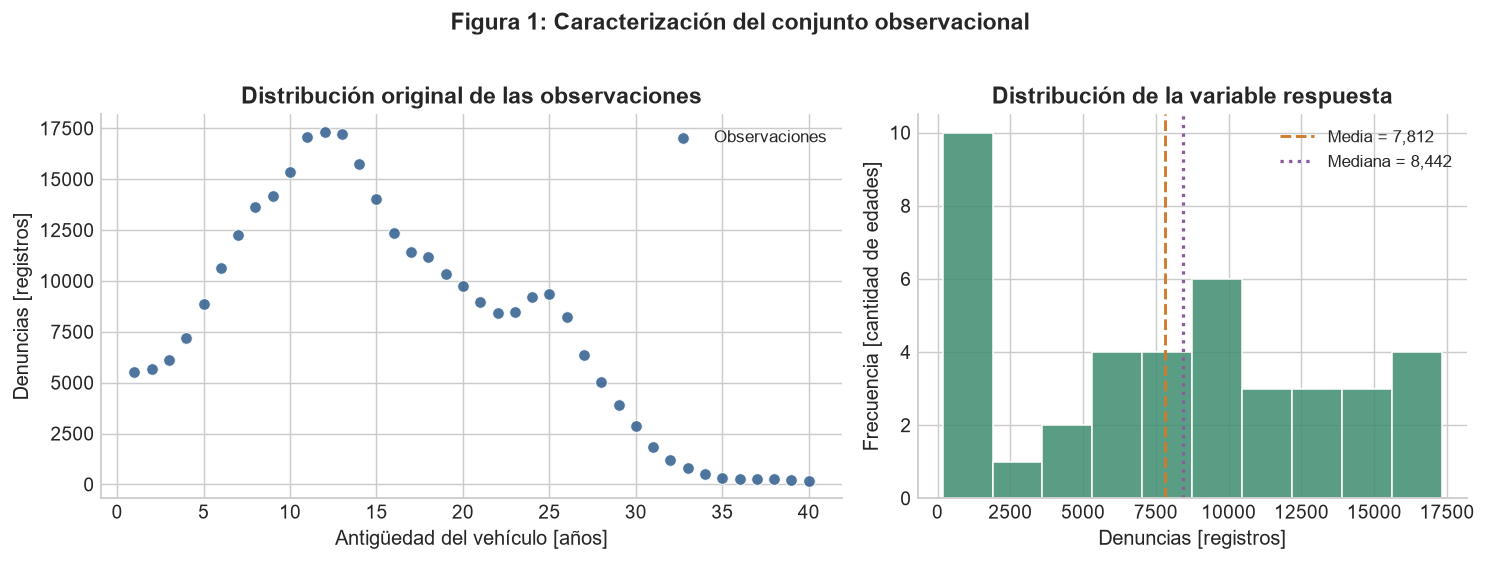

In [6]:
desc = pd.DataFrame({
    "estadístico": ["n", "mínimo", "máximo", "media", "mediana", "desvío estándar", "CV", "asimetría", "curtosis"],
    "x [años]": [len(pares), pares.x.min(), pares.x.max(), pares.x.mean(), pares.x.median(),
                 pares.x.std(ddof=1), pares.x.std(ddof=1)/pares.x.mean(), stats.skew(pares.x), stats.kurtosis(pares.x)],
    "y [denuncias]": [len(pares), pares.y.min(), pares.y.max(), pares.y.mean(), pares.y.median(),
                      pares.y.std(ddof=1), pares.y.std(ddof=1)/pares.y.mean(), stats.skew(pares.y), stats.kurtosis(pares.y)],
}).set_index("estadístico")
display(desc.style.format("{:,.4f}"))

r_p = stats.pearsonr(pares.x, pares.y)
r_s = stats.spearmanr(pares.x, pares.y)
print(f"Pearson r = {r_p.statistic:.4f} (p = {r_p.pvalue:.3g})")
print(f"Spearman rho = {r_s.statistic:.4f} (p = {r_s.pvalue:.3g})")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
ax[0].scatter(pares.x, pares.y, s=42, color=DATA_COLOR, alpha=.85, edgecolor="white", linewidth=.6, label="Observaciones")
ax[0].set(xlabel="Antigüedad del vehículo [años]", ylabel="Denuncias [registros]",
          title="Distribución original de las observaciones")
ax[0].legend(loc="upper right")
ax[1].hist(pares.y, bins=10, color=PALETTE[2], edgecolor="white", alpha=.85)
ax[1].axvline(pares.y.mean(), color=PALETTE[1], ls="--", lw=1.6, label=f"Media = {pares.y.mean():,.0f}")
ax[1].axvline(pares.y.median(), color=PALETTE[3], ls=":", lw=1.8, label=f"Mediana = {pares.y.median():,.0f}")
ax[1].set(xlabel="Denuncias [registros]", ylabel="Frecuencia [cantidad de edades]",
          title="Distribución de la variable respuesta")
ax[1].legend()
fig.suptitle("Figura 1: Caracterización del conjunto observacional", fontweight="bold", y=1.02)
fig.tight_layout(); plt.show()

## 5. Fundamento matemático del método de mínimos cuadrados

### 5.1 Problema de optimización

Dado un conjunto de $n$ observaciones $(x_i,y_i)$ y una familia de modelos $f(x;\boldsymbol{\beta})$ con $p$ parámetros, el criterio de mínimos cuadrados ordinarios (MCO) define

$$
\min_{\boldsymbol{\beta}}\; S(\boldsymbol{\beta}) = \sum_{i=1}^{n} \left( y_i - f(x_i;\boldsymbol{\beta}) \right)^2 .
$$

La **función objetivo** $S$ mide la discrepancia cuadrática total. Los **residuos** $\hat\varepsilon_i = y_i - \hat y_i = y_i - f(x_i;\hat{\boldsymbol{\beta}})$ son las desviaciones observadas respecto de la curva ajustada; $\hat{\boldsymbol{\beta}}$ denota el vector de **parámetros estimados**. La minimización equivale a proyectar ortogonalmente el vector de respuestas $\mathbf y$ sobre el espacio generado por las columnas de la matriz de diseño $\mathbf X$.

### 5.2 Condiciones de optimalidad

Si $f$ es diferenciable respecto de los parámetros, un mínimo interior satisface

$$
\left.\frac{\partial S}{\partial \beta_k}\right|_{\hat{\boldsymbol{\beta}}} = -2\sum_{i=1}^{n} \hat\varepsilon_i \;
\frac{\partial f(x_i;\hat{\boldsymbol{\beta}})}{\partial \beta_k} = 0, \qquad k=1,\ldots,p .
$$

**Desarrollo paso a paso.** Al derivar $S=\sum_i (y_i-f_i)^2$ respecto de $\beta_k$, la regla de la cadena da $\partial S/\partial\beta_k = -2\sum_i (y_i-f_i)\,\partial f_i/\partial\beta_k$. Igualar a cero y dividir por $-2$ lleva a la condición de **ortogonalidad**: el vector de residuos $\hat{\boldsymbol\varepsilon}$ es perpendicular a cada columna de la jacobiana $\mathbf J$, con $J_{ik}=\partial f_i/\partial\beta_k$, es decir

$$
\mathbf J^\top \hat{\boldsymbol\varepsilon} = \mathbf 0 .
$$

En el caso lineal en los parámetros, $f_i=\mathbf x_i^\top\boldsymbol\beta$ y $\mathbf J=\mathbf X$, por lo que se obtiene la forma matricial

$$
\mathbf y = \mathbf X\boldsymbol{\beta} + \boldsymbol{\varepsilon}, \qquad
\mathbf X^\top\mathbf X\,\hat{\boldsymbol{\beta}} = \mathbf X^\top\mathbf y .
$$

**Origen de las ecuaciones normales.** Sustituyendo $\hat{\boldsymbol\varepsilon}=\mathbf y-\mathbf X\hat{\boldsymbol\beta}$ en $\mathbf X^\top\hat{\boldsymbol\varepsilon}=\mathbf 0$ resulta $\mathbf X^\top\mathbf y-\mathbf X^\top\mathbf X\hat{\boldsymbol\beta}=\mathbf 0$. Si $\mathbf X$ tiene rango columnal completo, la solución formal es

$$
\hat{\boldsymbol{\beta}} = (\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y .
$$

La interpretación geométrica es precisa: $\hat{\mathbf y} = \mathbf X\hat{\boldsymbol{\beta}} = \mathbf H\mathbf y$, con $\mathbf H = \mathbf X(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top$ la matriz sombrero, proyector ortogonal sobre $\mathrm{col}(\mathbf X)$. El proyector complementario genera los residuos y cumple tres propiedades verificables en código:

$$
\hat{\boldsymbol\varepsilon}=(\mathbf I-\mathbf H)\mathbf y, \qquad
\mathbf H^2=\mathbf H, \qquad \mathbf H^\top=\mathbf H, \qquad \operatorname{tr}(\mathbf H)=p+1 .
$$

**Caso lineal simple, fórmula cerrada.** Para $y_i=a x_i+b+e_i$, con $\bar x=\frac1n\sum_i x_i$ y $\bar y=\frac1n\sum_i y_i$, se definen las sumas de cuadrados y productos cruzados

$$
S_{xx}=\sum_{i=1}^n(x_i-\bar x)^2,\qquad
S_{xy}=\sum_{i=1}^n(x_i-\bar x)(y_i-\bar y),\qquad
S_{yy}=\sum_{i=1}^n(y_i-\bar y)^2 .
$$

Las ecuaciones normales reducidas, $a S_{xx}=S_{xy}$ y $b=\bar y-a\bar x$, producen

$$
\hat a = \frac{S_{xy}}{S_{xx}}, \qquad \hat b = \bar y - \hat a\,\bar x, \qquad r=\frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}} .
$$

Estas expresiones son algebraicamente idénticas a la solución matricial y permiten verificar los coeficientes del modelo lineal sin invocar una librería de álgebra lineal.

### 5.3 Linealidad en los parámetros y linealidad en las variables

El modelo $y = a x^2 + b x + c$ es **lineal en los parámetros** aunque no lineal en $x$: su matriz de diseño es de Vandermonde. En cambio, $y = a x^{b}$ es no lineal en los parámetros: la transformación $\ln y = \ln a + b\ln x$ lo convierte en lineal *en los parámetros transformados*, pero modifica el criterio optimizado y la estructura del error. Esta distinción determina la estrategia numérica de cada modelo.

### 5.4 Estabilidad numérica

La formación de $\mathbf X^\top\mathbf X$ eleva al cuadrado el número de condición: $\kappa_2(\mathbf X^\top\mathbf X) = \kappa_2(\mathbf X)^2$, con $\kappa_2(\mathbf A)=\sigma_{\max}(\mathbf A)/\sigma_{\min}(\mathbf A)$. Para diseños polinómicos con $x$ no centrado, $\kappa_2$ crece rápidamente con el grado y la inversión explícita pierde cifras significativas.

La factorización QR escribe $\mathbf X=\mathbf Q\mathbf R$, con $\mathbf Q^\top\mathbf Q=\mathbf I$ y $\mathbf R$ triangular superior. Sustituyendo en las ecuaciones normales se obtiene un sistema triangular que se resuelve por sustitución hacia atrás:

$$
\mathbf R\hat{\boldsymbol\beta} = \mathbf Q^\top\mathbf y, \qquad \hat{\boldsymbol\beta}=\mathbf R^{-1}\mathbf Q^\top\mathbf y .
$$

La descomposición en valores singulares, $\mathbf X=\mathbf U\boldsymbol\Sigma\mathbf V^\top$, conduce a la seudoinversa de Moore-Penrose y a la solución de norma mínima

$$
\hat{\boldsymbol\beta}=\mathbf V\boldsymbol\Sigma^{-1}\mathbf U^\top\mathbf y, \qquad \boldsymbol\Sigma^{-1}=\operatorname{diag}\left(1/\sigma_1,\ldots,1/\sigma_p\right) .
$$

Ambas rutas, con SVD disponible mediante `numpy.linalg.lstsq`, evitan formar $\mathbf X^\top\mathbf X$ y son las que se emplean en los ajustes.

### 5.5 Limitaciones y sensibilidad

MCO asume errores de media cero, varianza constante e independientes del regresor para que los estimadores sean óptimos en el sentido de Gauss-Markov. La agregación por antigüedad produce datos de conteo, para los cuales la varianza suele crecer con la media: la heterocedasticidad es esperable y debe diagnosticarse. El criterio cuadrático otorga peso desproporcionado a observaciones extremas: un único valor atípico de alta influencia puede desplazar la curva. Finalmente, un buen ajuste muestral no garantiza validez predictiva fuera del rango observado; las curvas polinómicas, en particular, pueden divergir violentamente en extrapolación.

### 5.6 Verificación numérica de la estrategia de solución

Se cuantifica el número de condición del diseño cúbico sin escalar y se comparan tres rutas de cálculo: ecuaciones normales, QR y SVD (`lstsq`). Las tres rutas coinciden en precisión de máquina en este conjunto; sin embargo, $\kappa_2(\mathbf X^{T}\mathbf X)\approx1{,}3\times10^{10}$ frente a $\kappa_2(\mathbf X)\approx1{,}1\times10^{5}$ evidencia la amplificación cuadrática del número de condición al formar la matriz de Gram, y el escalado del regresor lo reduce a $\kappa_2\approx5{,}9$. En símbolos,

$$
\kappa_2(\mathbf X)\approx1{,}1\times10^{5},\qquad
\kappa_2(\mathbf X^\top\mathbf X)\approx1{,}3\times10^{10},\qquad
\kappa_2(\mathbf X_{\mathrm{esc}})\approx5{,}9,
\qquad \mathbf X_{\mathrm{esc}}=[\,\mathbf z^3,\mathbf z^2,\mathbf z,\mathbf 1\,],\quad z=\frac{x-\bar x}{s_x}.
$$

La cota de error relativo de la solución por ecuaciones normales crece como $\kappa_2(\mathbf X)^2\,\epsilon_{\mathrm{mach}}$, con $\epsilon_{\mathrm{mach}}\approx2{,}2\times10^{-16}$ en doble precisión.

In [7]:
x_all = pares.x.to_numpy(float)
y_all = pares.y.to_numpy(float)

def diseno(x, grado):
    return np.column_stack([x**k for k in range(grado, -1, -1)])

Xc = diseno(x_all, 3)
Xs = diseno((x_all - x_all.mean())/x_all.std(ddof=1), 3)
b_gram = np.linalg.solve(Xc.T @ Xc, Xc.T @ y_all)
Q, R = np.linalg.qr(Xc)
b_qr = np.linalg.solve(R, Q.T @ y_all)
b_svd = np.linalg.lstsq(Xc, y_all, rcond=None)[0]

cmp = pd.DataFrame({
    "método": ["Ecuaciones normales", "QR", "SVD / lstsq"],
    "diferencia máx. rel. vs SVD": [
        np.max(np.abs(b_gram-b_svd))/np.max(np.abs(b_svd)),
        np.max(np.abs(b_qr-b_svd))/np.max(np.abs(b_svd)), 0.0],
})
display(cmp.style.format({"diferencia máx. rel. vs SVD": "{:.3e}"}))
print(f"kappa2(X) sin escalar = {np.linalg.cond(Xc):.3e}")
print(f"kappa2(X) centrado/escalado = {np.linalg.cond(Xs):.3e}")
print(f"kappa2(X^T X) sin escalar = {np.linalg.cond(Xc.T@Xc):.3e}")

,método,diferencia máx. rel. vs SVD
0,Ecuaciones normales,5.431e-13
1,QR,1.574e-15
2,SVD / lstsq,0.000e+00


kappa2(X) sin escalar = 1.132e+05
kappa2(X) centrado/escalado = 5.933e+00
kappa2(X^T X) sin escalar = 1.282e+10


## 6. Modelo 1: Ajuste lineal

$$
y = a x + b
$$

**Fundamento.** Constituye la aproximación de primer orden: la frecuencia de denuncias variaría a razón constante por cada año de antigüedad. El parámetro $a$ representa la variación esperada de denuncias por año adicional y $b$ el valor extrapolado en $x=0$, que carece de interpretación física cuando se trabaja con $x\ge 1$ y se reporta solo como parámetro algebraico. El diseño es $\mathbf X=[\,\mathbf x,\mathbf 1\,]$ y la estimación se realiza por SVD.

**Ecuaciones normales del ajuste.** Con $\boldsymbol\beta=(a,b)^\top$, el producto $\mathbf X^\top\mathbf X$ y el vector $\mathbf X^\top\mathbf y$ son

$$
\mathbf X^\top\mathbf X=
\begin{pmatrix}
\sum_i x_i^2 & \sum_i x_i \\
\sum_i x_i & n
\end{pmatrix},
\qquad
\mathbf X^\top\mathbf y=
\begin{pmatrix}
\sum_i x_i y_i \\
\sum_i y_i
\end{pmatrix}.
$$

El sistema $\mathbf X^\top\mathbf X\,\hat{\boldsymbol\beta}=\mathbf X^\top\mathbf y$ equivale a dos ecuaciones escalares y su solución es la vista en la sección 5.2:

$$
\hat a = \frac{n\sum_i x_i y_i-\sum_i x_i\sum_i y_i}{n\sum_i x_i^2-(\sum_i x_i)^2}
      = \frac{S_{xy}}{S_{xx}}, \qquad
\hat b = \bar y - \hat a\,\bar x .
$$

La curva ajustada, los residuos y su desvío muestral (con $n-2$ grados de libertad) son

$$
\hat y_i=\hat a x_i+\hat b, \qquad
\hat e_i=y_i-\hat y_i, \qquad
\hat\sigma_e=\sqrt{\frac{1}{n-2}\sum_{i=1}^n \hat e_i^2} .
$$

Coeficientes: a = -333.895 denuncias/año; b = 14,657.269 denuncias
Función ajustada: y_hat = -333.895 x + 14,657.269
Residuos: media = 0.00; desvío = 3,860.24


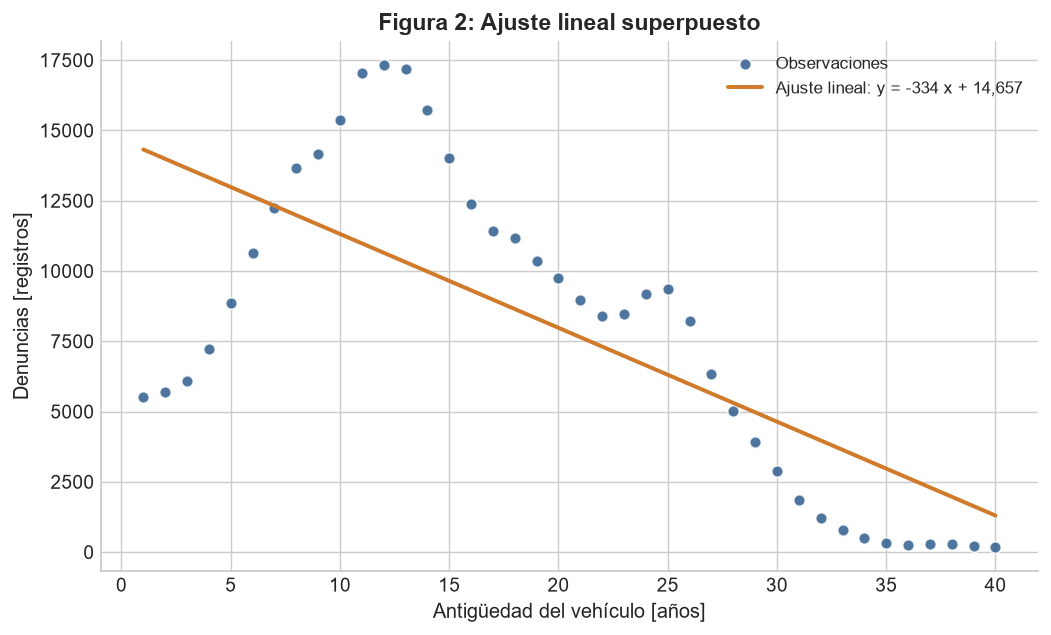

In [8]:
def ajustar_lineal(xt, yt, xv):
    A = np.column_stack([xt, np.ones_like(xt)])
    coef = np.linalg.lstsq(A, yt, rcond=None)[0]
    return coef, coef[0]*xv + coef[1]

beta_lin, yhat_lin = ajustar_lineal(x_all, y_all, x_all)
res_lin = y_all - yhat_lin

print(f"Coeficientes: a = {beta_lin[0]:,.3f} denuncias/año; b = {beta_lin[1]:,.3f} denuncias")
print(f"Función ajustada: y_hat = {beta_lin[0]:,.3f} x + {beta_lin[1]:,.3f}")
print(f"Residuos: media = {res_lin.mean():,.2f}; desvío = {res_lin.std(ddof=1):,.2f}")

fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(x_all, y_all, s=42, color=DATA_COLOR, alpha=.85, edgecolor="white", label="Observaciones")
ax.plot(x_all, yhat_lin, color=FIT_COLORS[0], lw=2.2,
        label=f"Ajuste lineal: y = {beta_lin[0]:,.0f} x + {beta_lin[1]:,.0f}")
ax.set(xlabel="Antigüedad del vehículo [años]", ylabel="Denuncias [registros]",
       title="Figura 2: Ajuste lineal superpuesto")
ax.legend(); fig.tight_layout(); plt.show()

## 7. Modelo 2: Ajuste potencial

$$
y = a x^{b}, \qquad a>0,\; x>0 .
$$

**Linealización.** Tomando logaritmos naturales:

$$
\ln y = \ln a + b \ln x \;\equiv\; \alpha + b\,\ln x .
$$

El modelo transformado es lineal en $(\alpha,b)$ y se estima por MCO sobre $(\ln x,\ln y)$. La pendiente $b$ es la elasticidad de las denuncias respecto de la antigüedad; $a=e^{\alpha}$.

**Cálculo en escala logarítmica.** Con $u_i=\ln x_i$, $v_i=\ln y_i$, $\bar u=\frac1n\sum_i u_i$ y $\bar v=\frac1n\sum_i v_i$, los estimadores y el criterio minimizado son

$$
\hat b=\frac{\sum_i(u_i-\bar u)(v_i-\bar v)}{\sum_i(u_i-\bar u)^2}, \qquad
\hat\alpha=\bar v-\hat b\,\bar u, \qquad \hat a=e^{\hat\alpha}, \qquad
S_{\log}=\sum_{i=1}^n\left(v_i-\hat\alpha-\hat b u_i\right)^2 .
$$

**Condiciones de validez e implicancias.** Se requiere $x>0$ e $y>0$ (ambas satisfechas en el subconjunto analizado) y se supone un error multiplicativo $y_i=a x_i^b\,\varepsilon_i$ con $\ln\varepsilon_i$ de media cero y varianza constante. Bajo ese supuesto, la regresión logarítmica estima la **mediana condicional** en la escala original, no la media. La retransformación directa $\hat y=e^{\hat\alpha}x^{\hat b}$ es sesgada hacia abajo para la media; se aplica el factor de corrección de Duan (1983),

$$
\hat e_i=v_i-\hat\alpha-\hat b u_i, \qquad
\hat s=\frac{1}{n}\sum_{i=1}^{n}\exp(\hat e_i), \qquad
\hat y_i^{\mathrm{Duan}}=\hat s\,e^{\hat\alpha}x_i^{\hat b},
$$

calculado **exclusivamente con residuos de entrenamiento**. Es fundamental destacar que este procedimiento **no minimiza $\sum (y_i-\hat y_i)^2$**, sino $S_{\log}$. Por ello se reporta, como diagnóstico, un ajuste alternativo por mínimos cuadrados no lineales directamente sobre la escala original, que minimiza

$$
S_{\mathrm{NLS}}(a,b)=\sum_{i=1}^n\left(y_i-a x_i^b\right)^2 .
$$

Log-log: b = -0.8567; ln(a) = 10.7353; a = 45,947.46
Factor de smearing de Duan = 1.6806
NLS en escala original: a = 12,912.03; b = -0.1839
SSE log-lineal = 8,106,233,648 | SSE NLS = 1,055,123,585


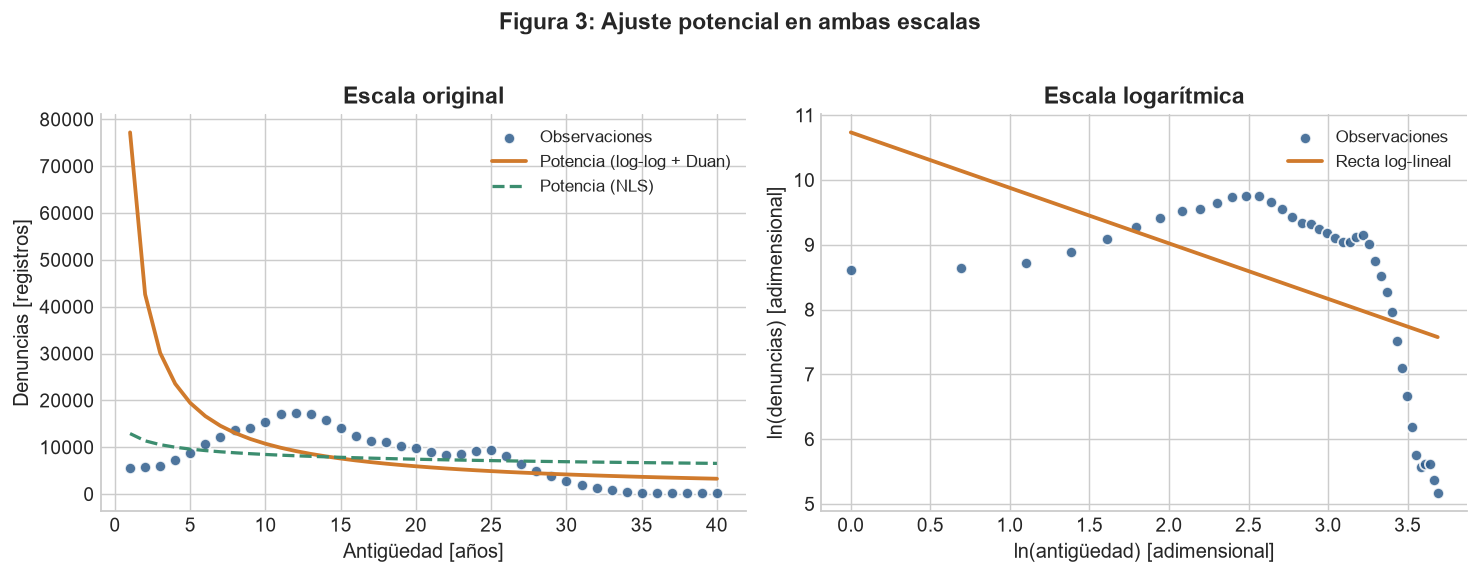

In [9]:
def ajustar_potencia_log(xt, yt, xv):
    m = xt > 0
    lx, ly = np.log(xt[m]), np.log(yt[m])
    A = np.column_stack([lx, np.ones(m.sum())])
    coef = np.linalg.lstsq(A, ly, rcond=None)[0]      # (b, alpha)
    smearing = np.mean(np.exp(ly - A @ coef))
    pred = np.full_like(xv, np.nan, dtype=float)
    ok = xv > 0
    pred[ok] = np.exp(coef[1]) * np.maximum(xv[ok], 1e-12)**coef[0] * smearing
    return coef, smearing, pred

coef_p, smear, yhat_pow = ajustar_potencia_log(x_all, y_all, x_all)
res_pow = y_all - yhat_pow

from scipy.optimize import curve_fit
def _pot(x, a, b): return a * np.maximum(x, 1e-12)**b
p0 = [np.exp(coef_p[1]), coef_p[0]]
popt, _ = curve_fit(_pot, x_all, y_all, p0=p0, maxfev=20000)
yhat_pow_nls = _pot(x_all, *popt)

print(f"Log-log: b = {coef_p[0]:.4f}; ln(a) = {coef_p[1]:.4f}; a = {np.exp(coef_p[1]):,.2f}")
print(f"Factor de smearing de Duan = {smear:.4f}")
print(f"NLS en escala original: a = {popt[0]:,.2f}; b = {popt[1]:.4f}")
print(f"SSE log-lineal = {np.sum(res_pow**2):,.0f} | SSE NLS = {np.sum((y_all-yhat_pow_nls)**2):,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
ax[0].scatter(x_all, y_all, s=38, color=DATA_COLOR, alpha=.85, edgecolor="white", label="Observaciones")
ax[0].plot(x_all, yhat_pow, color=FIT_COLORS[0], lw=2.1, label="Potencia (log-log + Duan)")
ax[0].plot(x_all, yhat_pow_nls, color=FIT_COLORS[1], lw=1.8, ls="--", label="Potencia (NLS)")
ax[0].set(xlabel="Antigüedad [años]", ylabel="Denuncias [registros]", title="Escala original")
ax[0].legend()
ax[1].scatter(np.log(x_all), np.log(y_all), s=38, color=DATA_COLOR, alpha=.85, edgecolor="white", label="Observaciones")
xx = np.linspace(np.log(1), np.log(40), 200)
ax[1].plot(xx, coef_p[1] + coef_p[0]*xx, color=FIT_COLORS[0], lw=2.1, label="Recta log-lineal")
ax[1].set(xlabel="ln(antigüedad) [adimensional]", ylabel="ln(denuncias) [adimensional]",
          title="Escala logarítmica")
ax[1].legend()
fig.suptitle("Figura 3: Ajuste potencial en ambas escalas", fontweight="bold", y=1.02)
fig.tight_layout(); plt.show()

## 8. Modelo 3: Polinomio cúbico y justificación previa

La Figura 1 muestra una trayectoria claramente no monótona: las denuncias crecen entre 1 y 12–13 años, descienden hasta 22 años, presentan un hombro secundario hacia 24–25 años y luego decrecen abruptamente. Esta forma descarta tanto una tendencia lineal decreciente como una ley potencial monótona.

Se selecciona un **polinomio de tercer grado**,

$$
y = c_3 x^3 + c_2 x^2 + c_1 x + c_0,
$$

por tres razones: (i) un cuadrático, con una sola curvatura, no puede reproducir el máximo y la recuperación intermedia posterior; (ii) el cúbico posee un parámetro adicional respecto del cuadrático y su elección debe validarse fuera de muestra; (iii) permanece lineal en los parámetros, por lo que su estimación admite QR/SVD sin requerir optimización no lineal. El costo es una interpretación física menos directa y una sensibilidad elevada en extrapolación.

**Cálculos derivados del ajuste.** El diseño y el vector de coeficientes son

$$
\mathbf X=[\,\mathbf x^3,\mathbf x^2,\mathbf x,\mathbf 1\,], \qquad
\hat{\boldsymbol c}=(\hat c_3,\hat c_2,\hat c_1,\hat c_0)^\top
=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y .
$$

La variación marginal y la aceleración de la frecuencia respecto de la antigüedad resultan de derivar la curva estimada:

$$
\hat y'(x)=3\hat c_3 x^2+2\hat c_2 x+\hat c_1, \qquad
\hat y''(x)=6\hat c_3 x+2\hat c_2 .
$$

Los puntos críticos son las raíces reales de $\hat y'(x)=0$ dentro del dominio observado:

$$
x_{\pm}=\frac{-2\hat c_2\pm\sqrt{4\hat c_2^2-12\hat c_3\hat c_1}}{6\hat c_3},
$$

y se clasifican como máximo o mínimo según el signo de $\hat y''(x_{\pm})$. La subsección 8.1 cuantifica la decisión del grado mediante validación cruzada.

Coeficientes [x^3, x^2, x, 1]: [ 1.8532e+00 -1.3762e+02  2.5280e+03  1.0087e+03]
Función ajustada: y_hat = 1.853e+00 x^3 -1.376e+02 x^2 +2.528e+03 x +1008.7
Puntos críticos en el dominio observado: ['37.33 años', '12.18 años']
Residuos: media = -0.00; desvío = 1,288.65


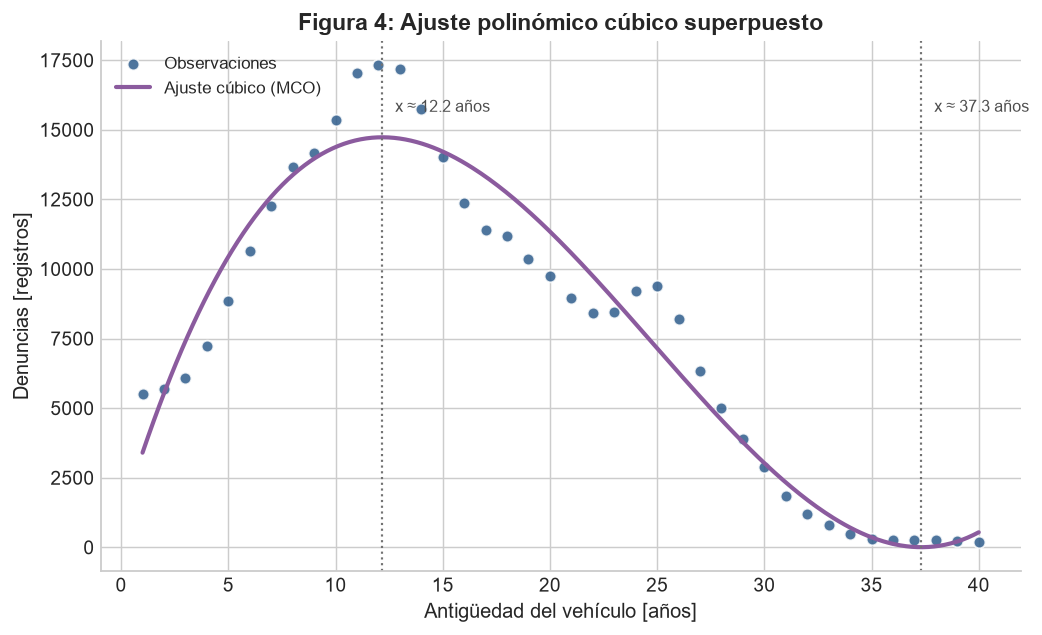

In [10]:
def ajustar_cubico(xt, yt, xv):
    A = diseno(xt, 3)
    coef = np.linalg.lstsq(A, yt, rcond=None)[0]
    return coef, diseno(xv, 3) @ coef

beta_cub, yhat_cub = ajustar_cubico(x_all, y_all, x_all)
res_cub = y_all - yhat_cub
der = np.poly1d(beta_cub).deriv()
raices = [r.real for r in der.r if abs(r.imag) < 1e-9 and x_all.min() <= r.real <= x_all.max()]

print("Coeficientes [x^3, x^2, x, 1]:", np.array2string(beta_cub, precision=4))
print("Función ajustada: y_hat = "
      f"{beta_cub[0]:.3e} x^3 {beta_cub[1]:+.3e} x^2 {beta_cub[2]:+.3e} x {beta_cub[3]:+.1f}")
print("Puntos críticos en el dominio observado:", [f"{r:.2f} años" for r in raices])
print(f"Residuos: media = {res_cub.mean():,.2f}; desvío = {res_cub.std(ddof=1):,.2f}")

fig, ax = plt.subplots(figsize=(8.2, 5))
ax.scatter(x_all, y_all, s=42, color=DATA_COLOR, alpha=.85, edgecolor="white", label="Observaciones")
xg = np.linspace(x_all.min(), x_all.max(), 300)
_, yg = ajustar_cubico(x_all, y_all, xg)
ax.plot(xg, yg, color=FIT_COLORS[2], lw=2.3, label="Ajuste cúbico (MCO)")
for r in raices:
    ax.axvline(r, color="0.45", ls=":", lw=1.2)
    ax.annotate(f"x ≈ {r:.1f} años", xy=(r, ax.get_ylim()[1]*.92), xytext=(r+0.6, ax.get_ylim()[1]*.86),
                fontsize=9, color="0.3")
ax.set(xlabel="Antigüedad del vehículo [años]", ylabel="Denuncias [registros]",
       title="Figura 4: Ajuste polinómico cúbico superpuesto")
ax.legend(); fig.tight_layout(); plt.show()

### 8.1 Justificación cuantitativa del grado polinómico

Antes de fijar el tercer modelo se compara, sobre los mismos datos y la misma partición de validación, un polinomio cuadrático y el cúbico. Ambos son lineales en los parámetros y se estiman por SVD; la única diferencia es el término de grado tres.

Para cada pliegue $k$, los coeficientes se estiman solo con el conjunto de entrenamiento $\mathcal T_k$ y se evalúan en $\mathcal V_k$. La métrica agregada es

$$
\mathrm{CV\_RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat y_i^{(-k(i))}\right)^2},
$$

donde $\hat y_i^{(-k(i))}$ denota la predicción del modelo entrenado sin la observación $i$.

In [11]:
def ajustar_cuadratico(xt, yt, xv):
    A = np.column_stack([xt**2, xt, np.ones_like(xt)])
    coef = np.linalg.lstsq(A, yt, rcond=None)[0]
    Av = np.column_stack([xv**2, xv, np.ones_like(xv)])
    return coef, Av @ coef

def cv_rmse_modelo(funcion, xt, yt):
    particion = KFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = np.full(len(yt), np.nan)
    for tr, te in particion.split(xt):
        oof[te] = funcion(xt[tr], yt[tr], xt[te])[1]
    return np.sqrt(np.mean((yt - oof)**2))

seleccion = []
for nombre, f in [("Cuadrático (2 parámetros)", ajustar_cuadratico), ("Cúbico (3 parámetros)", ajustar_cubico)]:
    _, pred = f(x_all, y_all, x_all)
    sse = float(np.sum((y_all - pred)**2))
    r2 = 1 - sse / float(np.sum((y_all - y_all.mean())**2))
    seleccion.append({"candidato": nombre, "R2": r2, "RMSE": np.sqrt(sse/len(y_all)),
                      "CV_RMSE": cv_rmse_modelo(f, x_all, y_all)})
display(pd.DataFrame(seleccion).set_index("candidato").style.format("{:,.3f}"))
print("El término cúbico reduce sustancialmente el error fuera de muestra: se adopta el grado tres.")
print("No se prueban grados superiores: no hay evidencia de estructura adicional y la extrapolación sería menos estable.")

,R2,RMSE,CV_RMSE
candidato,,,
Cuadrático (2 parámetros),0.775,"2,568.876","3,319.464"
Cúbico (3 parámetros),0.945,"1,272.444","1,408.122"


El término cúbico reduce sustancialmente el error fuera de muestra: se adopta el grado tres.
No se prueban grados superiores: no hay evidencia de estructura adicional y la extrapolación sería menos estable.


## 9. Evaluación y comparación de modelos

Para los tres ajustes se calculan, sobre la misma respuesta $y$ y la misma escala:

$$
SSE=\sum_{i=1}^{n}(y_i-\hat y_i)^2,\qquad
SST=\sum_{i=1}^{n}(y_i-\bar y)^2,\qquad
R^2=1-\frac{SSE}{SST},
$$

$$
MSE=\frac{SSE}{n},\qquad RMSE=\sqrt{MSE},\qquad
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.
$$

**Descomposición de la varianza.** Para modelos con término independiente se cumple la identidad

$$
SST = SSR + SSE, \qquad
SSR=\sum_{i=1}^n(\hat y_i-\bar y)^2,
$$

de modo que $R^2=SSR/SST$ mide la fracción de variabilidad explicada por la curva. Esta igualdad no vale para el ajuste potencial porque su retransformación no es lineal en la escala original: allí se calcula $R^2$ directamente como $1-SSE/SST$, pudiendo resultar negativo.

**Penalizaciones por complejidad.** Con $p+1$ parámetros (coeficientes más varianza) y $n$ observaciones:

$$
R^2_{\mathrm{aj}} = 1-(1-R^2)\frac{n-1}{n-p-1}, \qquad
AIC=n\ln\left(\frac{SSE}{n}\right)+2(p+1), \qquad
BIC=n\ln\left(\frac{SSE}{n}\right)+(p+1)\ln n .
$$

El logaritmo de verosimilitud gaussiana concentrada es $\ln\hat L=-\frac n2\left[1+\ln(2\pi)+\ln(SSE/n)\right]$, de donde surgen AIC $= -2\ln\hat L+2(p+1)$ y BIC $=-2\ln\hat L+(p+1)\ln n$ salvo constantes comunes a los tres modelos. Menor AIC/BIC indica mejor compromiso entre ajuste y complejidad. Ningún indicador se interpreta de forma aislada: la decisión final integra ajuste, estabilidad y validez predictiva.

,p,SSE,SST,R2,R2_aj,MSE,RMSE,MAE,AIC,BIC
Lineal,1.000,"581,156,954.833","1,175,376,079.775",0.506,0.493,"14,528,923.871","3,811.683","3,114.640",663.666,667.044
Potencial (log-log),2.000,"8,106,233,648.230","1,175,376,079.775",-5.897,-6.270,"202,655,841.206","14,235.724","7,306.947",771.081,776.147
Cúbico,3.000,"64,764,528.894","1,175,376,079.775",0.945,0.940,"1,619,113.222","1,272.444",996.552,579.896,586.651


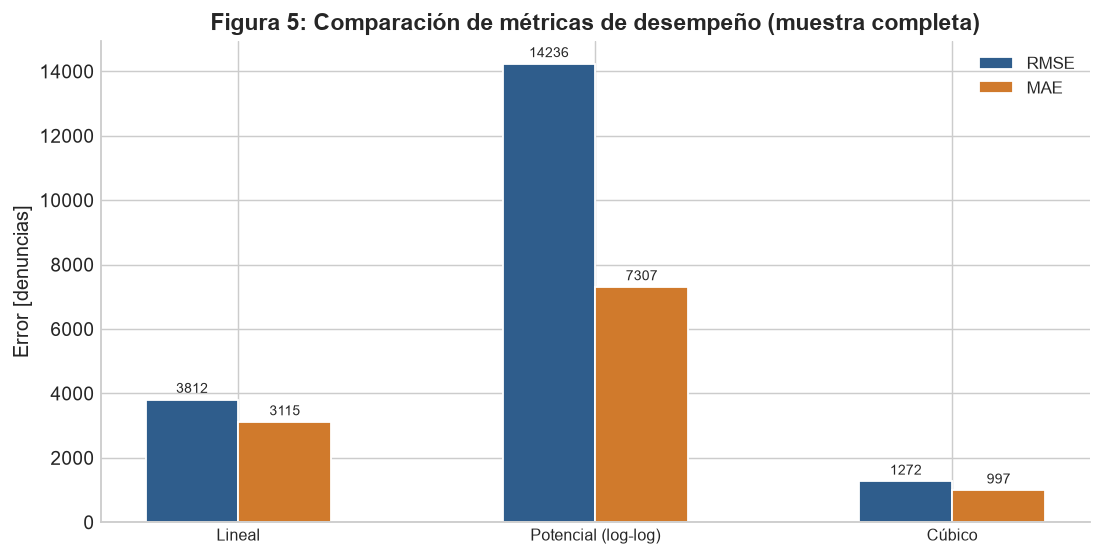

In [12]:
def metricas(y, yhat, p):
    e = y - yhat; n = len(y)
    sse = float(e @ e); sst = float(((y-y.mean())**2).sum())
    r2 = 1 - sse/sst; mse = sse/n
    return {"p": p, "SSE": sse, "SST": sst, "R2": r2,
            "R2_aj": 1-(1-r2)*(n-1)/(n-p-1), "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": float(np.mean(np.abs(e))),
            "AIC": n*np.log(sse/n)+2*(p+1), "BIC": n*np.log(sse/n)+(p+1)*np.log(n)}

tabla = pd.DataFrame({
    "Lineal": metricas(y_all, yhat_lin, 1),
    "Potencial (log-log)": metricas(y_all, yhat_pow, 2),
    "Cúbico": metricas(y_all, yhat_cub, 3),
}).T
display(tabla.style.format("{:,.3f}"))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
inder = np.arange(len(tabla)); ancho = 0.26
for j, col in enumerate(["RMSE", "MAE"]):
    barras = ax.bar(inder + (j-0.5)*ancho, tabla[col], ancho,
                    color=PALETTE[j], label=col, edgecolor="white")
    ax.bar_label(barras, fmt="%.0f", padding=2, fontsize=8)
ax.set_xticks(inder); ax.set_xticklabels(tabla.index, fontsize=9)
ax.set(ylabel="Error [denuncias]", title="Figura 5: Comparación de métricas de desempeño (muestra completa)")
ax.legend(); fig.tight_layout(); plt.show()

### 9.1 Validación fuera de muestra sin fuga de información

Se emplea validación cruzada mediante particiones aleatorias de cinco pliegues (`KFold`, semilla 2026). Todas las operaciones dependientes de los datos (estimación de coeficientes, factor de smearing de Duan y escalado) se ejecutan **dentro de cada pliegue de entrenamiento**; las observaciones de validación intervienen solo en el cálculo del error. Si $\mathcal T_k$ y $\mathcal V_k$ son los conjuntos de entrenamiento y validación del pliegue $k$, entonces

$$
\hat y_i^{(-k)} = f\!\left(x_i;\hat{\boldsymbol\beta}_{(\mathcal T_k)}\right),\quad i\in\mathcal V_k, \qquad
\mathrm{CV\_RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n\left(y_i-\hat y_i^{(-k(i))}\right)^2}.
$$

Las predicciones fuera de muestra se concatenan para obtener RMSE, MAE y $R^2$ de validación.

,CV_RMSE,CV_MAE,CV_R2
modelo,,,
Lineal,"4,029.494","3,263.318",0.447
Potencial (log-log),"32,023.041","11,170.510",-33.899
Cúbico,"1,408.122","1,096.442",0.933


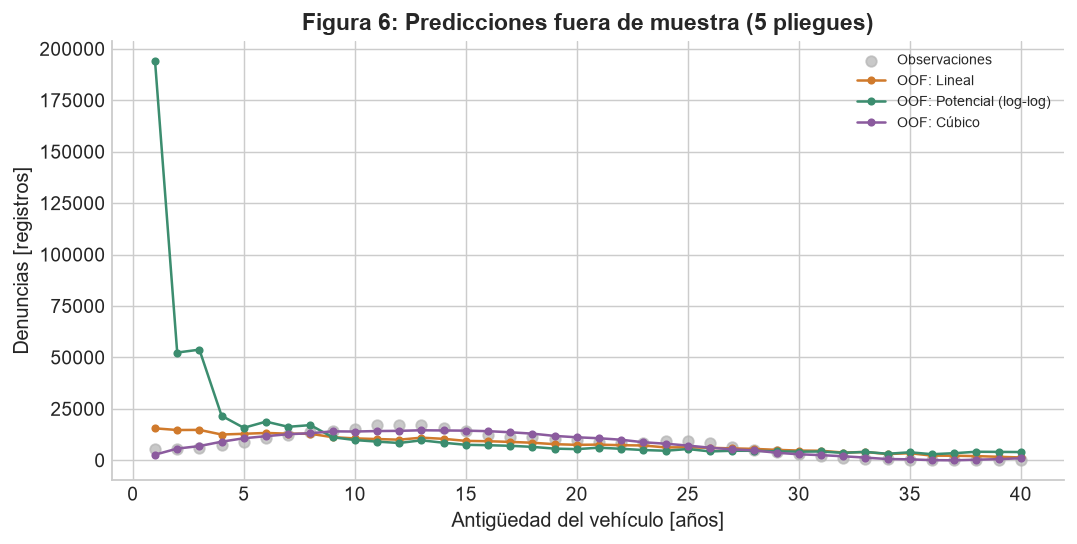

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
modelos = {
    "Lineal": ajustar_lineal,
    "Potencial (log-log)": ajustar_potencia_log,
    "Cúbico": ajustar_cubico,
}
predicciones_oof = {}
for nombre, funcion in modelos.items():
    oof = np.full(len(y_all), np.nan)
    for idx_tr, idx_te in kf.split(x_all):
        if nombre == "Potencial (log-log)":
            _, _, pte = funcion(x_all[idx_tr], y_all[idx_tr], x_all[idx_te])
        else:
            _, pte = funcion(x_all[idx_tr], y_all[idx_tr], x_all[idx_te])
        oof[idx_te] = pte
    predicciones_oof[nombre] = oof

filas = []
for nombre, pred in predicciones_oof.items():
    e = y_all - pred; sse = float(e@e); sst = float(((y_all-y_all.mean())**2).sum())
    filas.append({"modelo": nombre, "CV_RMSE": np.sqrt(sse/len(y_all)),
                  "CV_MAE": float(np.mean(np.abs(e))), "CV_R2": 1-sse/sst})
cv = pd.DataFrame(filas).set_index("modelo")
display(cv.style.format("{:,.3f}"))

fig, ax = plt.subplots(figsize=(8.4, 4.3))
ax.scatter(x_all, y_all, s=34, color="0.7", alpha=.7, label="Observaciones")
for i, (nombre, color) in enumerate(zip(modelos, PALETTE[1:])):
    ax.plot(x_all, predicciones_oof[nombre], marker="o", ms=3.5, lw=1.4,
            color=color, label=f"OOF: {nombre}")
ax.set(xlabel="Antigüedad del vehículo [años]", ylabel="Denuncias [registros]",
       title="Figura 6: Predicciones fuera de muestra (5 pliegues)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 10. Análisis de residuos

El diagnóstico comprende tres vistas complementarias por modelo: residuos versus valores ajustados, histograma con densidad normal de referencia y gráfico cuantil-cuantil. Se complementa con la prueba de Breusch-Pagan (heterocedasticidad), Shapiro-Wilk (normalidad), Durbin-Watson (autocorrelación a lo largo de la antigüedad) y el sesgo medio. Una estructura sistemática en los residuos invalida la interpretación del $R^2$ como evidencia de calidad del modelo.

**Definiciones y estadísticos de prueba.** El residuo y su media muestral son $\hat e_i=y_i-\hat y_i$ y $\bar e=\frac1n\sum_i\hat e_i$. Breusch-Pagan regresa el cuadrado de los residuos sobre los ajustes,

$$
\hat e_i^2 = \gamma_0+\gamma_1\hat y_i+u_i, \qquad
LM = n\,R^2_{\mathrm{aux}} \;\xrightarrow{\;H_0\;}\; \chi^2_1,
$$

mientras que Durbin-Watson mide la dependencia serial de residuos ordenados por antigüedad:

$$
DW = \frac{\sum_{i=2}^{n}\left(\hat e_i-\hat e_{i-1}\right)^2}{\sum_{i=1}^{n}\hat e_i^2},
\qquad DW\approx 2 \Leftrightarrow \text{sin autocorrelación lineal}.
$$

El valor $DW<2$ indica autocorrelación positiva y $DW>2$, negativa. Shapiro-Wilk contrasta la normalidad de $\hat e_i$ comparando la recta teórica del gráfico cuantil-cuantil con los cuantiles observados.

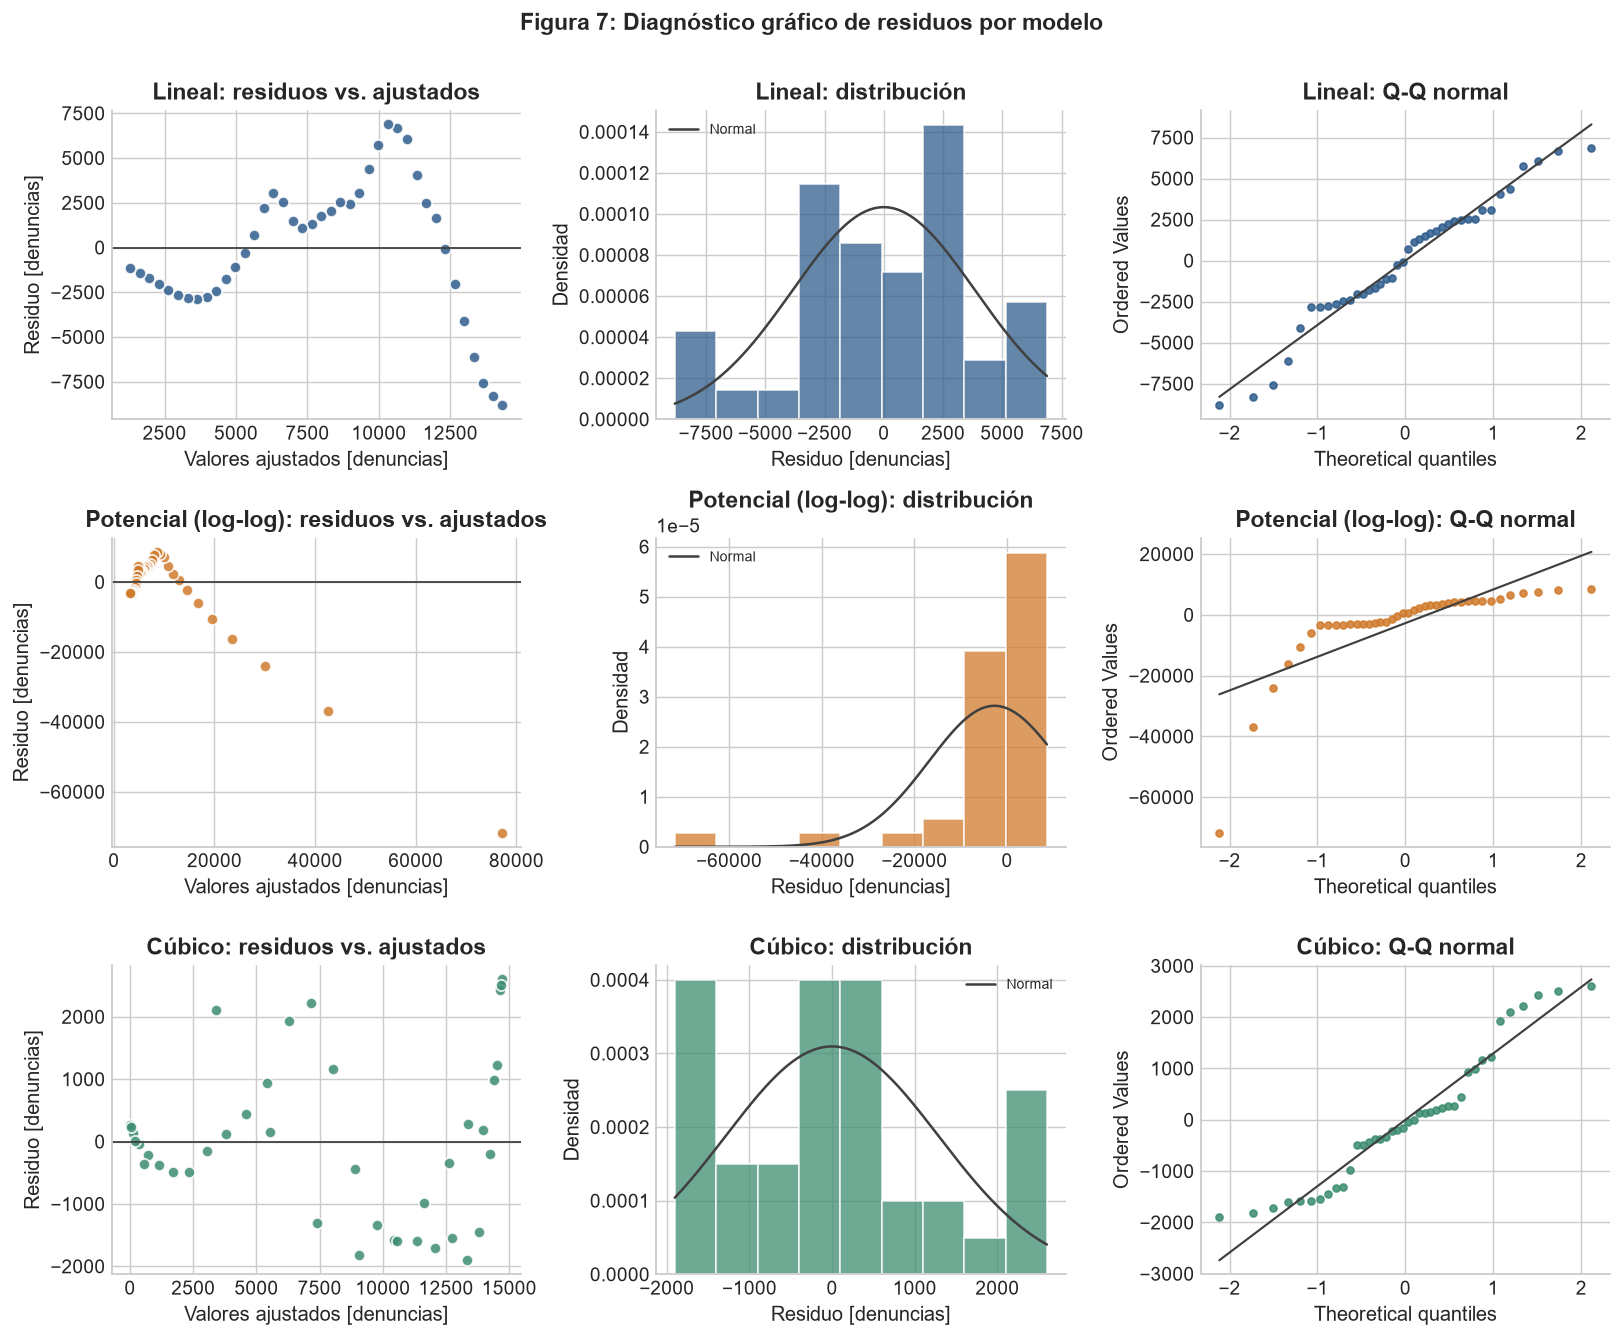

,media residuo,BP LM p-valor,Shapiro p-valor,Durbin-Watson
modelo,,,,
Lineal,0.00,8.53e-05,0.28,0.068
Potencial (log-log),"-2,707.01",7.02e-09,3e-09,0.190
Cúbico,-0.00,0.00175,0.0235,0.344


In [14]:
residuos = {"Lineal": res_lin, "Potencial (log-log)": res_pow, "Cúbico": res_cub}
ajustes = {"Lineal": yhat_lin, "Potencial (log-log)": yhat_pow, "Cúbico": yhat_cub}

fig, axes = plt.subplots(3, 3, figsize=(12.6, 10.2))
for i, nombre in enumerate(residuos):
    e, yh = residuos[nombre], ajustes[nombre]
    axes[i, 0].scatter(yh, e, s=38, color=PALETTE[i], alpha=.85, edgecolor="white")
    axes[i, 0].axhline(0, color="0.25", lw=1)
    axes[i, 0].set(xlabel="Valores ajustados [denuncias]", ylabel="Residuo [denuncias]",
                   title=f"{nombre}: residuos vs. ajustados")
    axes[i, 1].hist(e, bins=9, density=True, color=PALETTE[i], alpha=.75, edgecolor="white")
    xs = np.linspace(e.min(), e.max(), 200)
    axes[i, 1].plot(xs, stats.norm.pdf(xs, e.mean(), e.std(ddof=1)), color="0.25", lw=1.4, label="Normal")
    axes[i, 1].set(xlabel="Residuo [denuncias]", ylabel="Densidad", title=f"{nombre}: distribución")
    axes[i, 1].legend(fontsize=8)
    stats.probplot(e, dist="norm", plot=axes[i, 2])
    axes[i, 2].get_lines()[0].set(marker="o", ms=3.8, color=PALETTE[i], alpha=.85)
    axes[i, 2].get_lines()[1].set(color="0.25", lw=1.2)
    axes[i, 2].set_title(f"{nombre}: Q-Q normal")
fig.suptitle("Figura 7: Diagnóstico gráfico de residuos por modelo", fontweight="bold", y=1.005)
fig.tight_layout(); plt.show()

diag = []
for nombre, modelo in modelos.items():
    e = residuos[nombre]
    if nombre == "Potencial (log-log)":
        _, _, yhat_i = ajustar_potencia_log(x_all, y_all, x_all)
    else:
        _, yhat_i = modelo(x_all, y_all, x_all)
    bp = het_breuschpagan(e, np.column_stack([np.ones_like(yhat_i), yhat_i]))
    sh = stats.shapiro(e)
    diag.append({"modelo": nombre, "media residuo": e.mean(),
                 "BP LM p-valor": bp[1], "Shapiro p-valor": sh.pvalue,
                 "Durbin-Watson": durbin_watson(e)})
diag = pd.DataFrame(diag).set_index("modelo")
display(diag.style.format({"media residuo": "{:,.2f}", "BP LM p-valor": "{:.3g}",
                           "Shapiro p-valor": "{:.3g}", "Durbin-Watson": "{:.3f}"}))

## 11. Comparación conjunta y análisis de sensibilidad

La superposición de las tres curvas sobre un mismo sistema de coordenadas permite comparar no solo el error global sino la región del dominio donde cada modelo diverge. Se evalúa además la sensibilidad de los ajustes lineal y cúbico a la reincorporación de la observación $x=0$, excluida únicamente por el dominio del logaritmo.

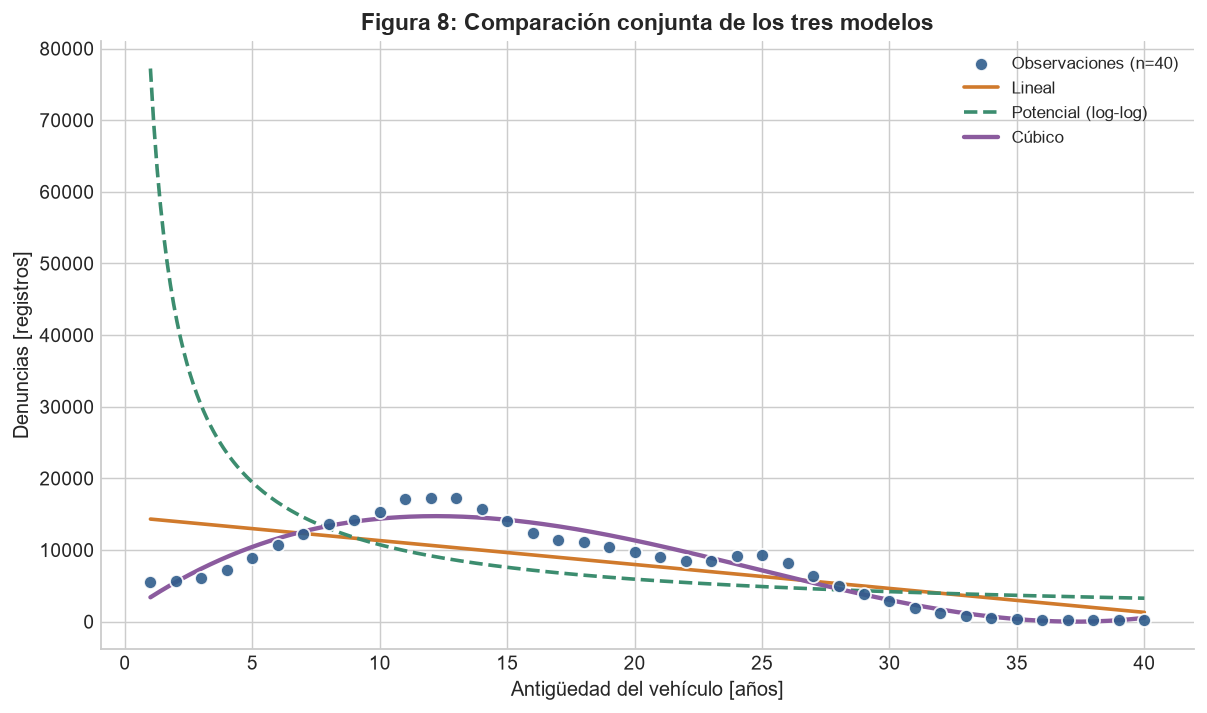

,RMSE x≥1,RMSE x≥0,Δ máx. predicción en x≥1 [denuncias]
modelo,,,
Lineal,"3,811.68","4,203.55","1,139.40"
Cúbico,"1,272.44","1,264.30",288.47


In [15]:
fig, ax = plt.subplots(figsize=(9.4, 5.6))
ax.scatter(x_all, y_all, s=52, color=DATA_COLOR, alpha=.9, edgecolor="white", zorder=4, label="Observaciones (n=40)")
_, ygrid_lin = ajustar_lineal(x_all, y_all, xg)
_, _, ygrid_pow = ajustar_potencia_log(x_all, y_all, xg)
_, ygrid_cub = ajustar_cubico(x_all, y_all, xg)
ax.plot(xg, ygrid_lin, lw=2, color=FIT_COLORS[0], label="Lineal")
ax.plot(xg, ygrid_pow, lw=2, color=FIT_COLORS[1], ls="--", label="Potencial (log-log)")
ax.plot(xg, ygrid_cub, lw=2.4, color=FIT_COLORS[2], label="Cúbico")
ax.set(xlabel="Antigüedad del vehículo [años]", ylabel="Denuncias [registros]",
       title="Figura 8: Comparación conjunta de los tres modelos")
ax.legend(); fig.tight_layout(); plt.show()

x0 = conteo_full["edad"].to_numpy(float); y0 = conteo_full["y"].to_numpy(float)
sens = []
for nombre, f in [("Lineal", ajustar_lineal), ("Cúbico", ajustar_cubico)]:
    b40, p40 = f(x_all, y_all, x_all)
    b41, p41 = f(x0, y0, x0)
    _, p41_en_x1 = f(x0, y0, x_all)
    sens.append({"modelo": nombre, "RMSE x≥1": np.sqrt(np.mean((y_all-p40)**2)),
                 "RMSE x≥0": np.sqrt(np.mean((y0-p41)**2)),
                 "Δ máx. predicción en x≥1 [denuncias]": np.max(np.abs(p40-p41_en_x1))})
display(pd.DataFrame(sens).set_index("modelo").style.format("{:,.2f}"))

## 12. Discusión técnica de resultados

### 12.1 Calidad del ajuste y comparación de modelos

El modelo cúbico domina en todos los criterios calculados sobre la escala original: presenta la menor SSE y RMSE, el mayor $R^2$ y $R^2_{\mathrm{aj}}$, y los valores más bajos de AIC y BIC. La sección 8.1 muestra que el término cúbico reduce sustancialmente el error de validación cruzada respecto del cuadrático, lo que indica que el parámetro adicional captura estructura real y no ruido: la curva describe el ascenso hasta 12–13 años y el descenso posterior. El hombro secundario en 24–25 años, presente en los datos, no constituye un extremo local del polinomio (solo hay dos puntos críticos, en 12,18 y 37,33 años) y explica parte de la estructura residual restante.

El ajuste lineal resulta insuficiente: su pendiente negativa ($-334$ denuncias/año) promedia en una única tasa el ascenso inicial y el descenso final. Su $R^2$ bajo y sus residuos con arcos sistemáticos evidencian falta de ajuste más que dispersión aleatoria.

El modelo potencial es estructuralmente incompatible con la forma observada. La ley $a x^{b}$ es monótona para $a>0$, mientras que la frecuencia observada es unimodal. El ajuste por linealización logarítmica minimiza errores relativos y otorga peso excesivo a las antigüedades extremas, donde los conteos son pequeños; al retransformar a la escala original, el factor de corrección de Duan no compensa la magnitud del error. Su $R^2$ negativo implica un desempeño peor que una línea horizontal, un resultado coherente con la incompatibilidad funcional y no con un defecto de implementación. El ajuste potencial directo por mínimos cuadrados no lineales reduce la SSE pero no remedia la falta de ajuste: confirma que la forma funcional, no la técnica de estimación, es la limitación.

### 12.2 Interpretación física de los parámetros

En el modelo lineal, el coeficiente de $x$ indica cambios constantes por año y no distingue entre vehículos relativamente nuevos y antiguos. En el modelo potencial, $b$ sería la elasticidad, pero su estimación no es interpretable aquí porque el supuesto de monotonicidad falla. En el modelo cúbico, las derivadas primera y segunda describen la variación marginal y la aceleración de la frecuencia respecto de la antigüedad; los puntos críticos localizan los máximos y mínimos relativos dentro del dominio observado. Estos parámetros son descriptivos de la distribución empírica de la flota denunciada, no estimaciones causales del riesgo de sustracción por año de antigüedad: la composición de la flota circulante por cohorte no se observa en este conjunto de datos y actúa como variable de confusión.

### 12.3 Residuos, heterocedasticidad y estabilidad

El modelo cúbico presenta residuos centrados en cero y la menor dispersión (desvío ≈ 1.289 denuncias), pero no está libre de estructura: Durbin–Watson ≈ 0,34 indica dependencia serial a lo largo de la antigüedad y Breusch–Pagan ($p\approx1{,}8\times10^{-3}$) revela heterocedasticidad. Los otros dos modelos exhiben estructuras más pronunciadas; el potencial, además, presenta un sesgo medio de $-2.707$ denuncias. La prueba de Breusch–Pagan y el gráfico Q-Q cuantifican heterocedasticidad y desviación de normalidad, esperables en datos de conteo agregado: la inferencia clásica basada en errores homocedásticos debe interpretarse con cautela y motivaría, en un estudio posterior, mínimos cuadrados ponderados o un modelo de conteo.

La estimación se realizó por SVD; la concordancia con QR y la magnitud del número de condición justifican evitar las ecuaciones normales. El escalado del regresor reduce drásticamente $\kappa_2$, aunque no altera los coeficientes en doble precisión para este tamaño muestral.

### 12.4 Complejidad y coherencia

El modelo cúbico incorpora un parámetro adicional respecto del cuadrático y tres respecto del lineal, con una ganancia predictiva ampliamente superior en validación cruzada. No se justifica incrementar el grado a cuatro o superior: aumentaría la inestabilidad en los extremos sin evidencia de estructura adicional. La elección final conjuga ajuste, parsimonia relativa, diagnóstico de residuos y coherencia con la forma empírica.

## 13. Conclusiones

1. La relación entre antigüedad vehicular y denuncias de robo o hurto es marcadamente no lineal y no monótona en el corpus DNRPA 2018–2026: las denuncias crecen hasta 12–13 años de antigüedad, descienden, presentan un hombro hacia 24–25 años y caen con rapidez en vehículos de más de 30 años.
2. El polinomio cúbico es el modelo más adecuado de los tres evaluados. Presenta el menor error en muestra y fuera de muestra, el mayor $R^2$ ajustado y los menores AIC/BIC, con residuos centrados y la menor estructura sistemática de los tres ajustes, aunque persisten dependencia serial y heterocedasticidad.
3. El ajuste lineal captura solo una tendencia media y presenta falta de ajuste sistemática. La ley potencial, estimada mediante linealización logarítmica, es incompatible con la forma de los datos; su desempeño ilustra que minimizar el error en escala logarítmica no equivale a minimizar el error cuadrático en la escala original.
4. La estrategia numérica basada en QR/SVD evita la amplificación del número de condición propia de las ecuaciones normales y produce coeficientes reproducibles.
5. Los resultados son descriptivos y están condicionados por la composición no observada de la flota y por la agregación anual de la antigüedad. No deben extrapolarse fuera de 1–40 años: los polinomios de grado tres divergen en los extremos y pueden predecir valores negativos.

**Trabajo posterior recomendado.** Incorporar la flota registrada por cohorte como denominador de exposición, emplear mínimos cuadrados ponderados o modelos Poisson/negativo binomial para la naturaleza de conteo, y extender el análisis a covariables administrativas ya disponibles (marca, tipo de uso y jurisdicción).

## 14. Referencias

- Dirección Nacional de los Registros Nacionales de la Propiedad del Automotor y Créditos Prendarios (2018–2026). *Robos y recuperos de autos* [Conjunto de datos]. República Argentina, Portal Datos Argentina. https://datos.gob.ar/dataset/robos-y-recuperos-de-autos
- Dirección Nacional de los Registros Nacionales de la Propiedad del Automotor y Créditos Prendarios. *Sitio institucional de referencia*. https://www.dnrpa.gov.ar
- McKinney, W. (2017). *Python for Data Analysis: Data Wrangling with Pandas, NumPy, and IPython* (2a ed.). O'Reilly Media.
- Walpole, R. E., Myers, R. H., Myers, S. L. y Ye, K. *Probabilidad y estadística para ingeniería y ciencias*.
- Strang, G. *Álgebra lineal en ciencia de datos*.
- Szretter Noste, M. E. *Apunte de regresión lineal*. Facultad de Ciencias Exactas y Naturales, Universidad de Buenos Aires.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.

### 14.1 Nota de reproducibilidad

Los datos crudos no se modifican. Todas las transformaciones, estimaciones, pruebas y figuras se generan en este notebook. La semilla de particionamiento es 2026. Las versiones de las bibliotecas se registran en la primera celda de código. El archivo `requirements.txt` del repositorio fija las dependencias necesarias.

In [16]:
resumen = pd.DataFrame({
    "modelo": list(tabla.index),
    "RMSE": tabla["RMSE"].values,
    "R2": tabla["R2"].values,
    "CV_RMSE": [cv.loc[m, "CV_RMSE"] for m in tabla.index],
    "AIC": tabla["AIC"].values,
}).set_index("modelo")
print("SÍNTESIS FINAL")
display(resumen.style.format("{:,.2f}"))
print("Mejor modelo por CV_RMSE:", cv["CV_RMSE"].idxmin())
print("Mejor modelo por AIC:", tabla["AIC"].idxmin())
print("Nota: el diagnóstico de residuos y las restricciones de dominio se integran en la discusión;")
print("       el criterio de selección no se apoya exclusivamente en R^2.")

SÍNTESIS FINAL


,RMSE,R2,CV_RMSE,AIC
modelo,,,,
Lineal,"3,811.68",0.51,"4,029.49",663.67
Potencial (log-log),"14,235.72",-5.90,"32,023.04",771.08
Cúbico,"1,272.44",0.94,"1,408.12",579.90


Mejor modelo por CV_RMSE: Cúbico
Mejor modelo por AIC: Cúbico
Nota: el diagnóstico de residuos y las restricciones de dominio se integran en la discusión;
       el criterio de selección no se apoya exclusivamente en R^2.
